# Gender pension gap analysis (Eurostat: ilc_pnp13 and ilc_pnp13m)

## Introduction & data overview

### Project objective

This analysis examines the gender pension gap among people aged 65+ across EU countries and at EU level. It compares average and median gender pension gaps to identify differences in their size and in country rankings.

### Indicator definitions
**Average gender pension gap by age group (ilc_pnp13)**

The average gender pension gap is defined as the difference between women’s and men’s average (gross) pension income, expressed in percentage.

Link to dataset: https://ec.europa.eu/eurostat/databrowser/view/ilc_pnp13__custom_23676646/default/table 

**Median gender pension gap by age group (ilc_pnp13m)**

The median gender pension gap is defined as the difference between women’s and men’s median (gross) pension income, expressed in percentage. 

Link to dataset: https://ec.europa.eu/eurostat/databrowser/view/ilc_pnp13m$defaultview/default/table?lang=en 

For both indicators, pension income includes old-age benefits, survivors’ benefits, and regular pensions from individual private plans.

**Period retrieved**: 2015–2025. Data availability may vary by country, year and indicator.


### Methodological notes
- The indicators are based on EU Statistics on Income and Living Conditions (EU-SILC).
- Income variables generally refer to the previous calendar year rather than the survey year.
- EU-SILC uses sample-based data, so published indicators are statistical estimates.
- Changes to the EU-SILC regulatory framework from 2021 should be considered when interpreting trends over time.

**Eurostat metadata:** https://ec.europa.eu/eurostat/cache/metadata/en/ilc_sieusilc.htm 

### Scope of this analysis
- **Geographical coverage**: 27 EU Member States and the Eurostat EU27_2020 aggregate
- **Age groups**: 65–74, 65–79 and 65+
- **Period**: 2015–2025
- **Unit**: percentage
- **Observation flags**: retained for checking and interpretation

**Observation flags**:
- (b): break in time series
- (e): estimated
- (p): provisional

# Data retrieval & preparation

**Source:** Eurostat (ilc_pnp13,ilc_pnp13m), EU_SILC

**Data retrieval**: API connection

# Eurostat ilc_pnp13: AVERAGE gender pension gap by age group

### Data upload and exploration

In [1]:
# Checking if Eurostat can be reached

import requests

url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/ilc_pnp13"
)

response = requests.get(url)

if response.status_code == 200:
    print("Eurostat API request successful (HTTP 200).")
else:
    print(f"Eurostat API request failed (HTTP {response.status_code}).")

Eurostat API request successful (HTTP 200).


In [2]:
# Converting the response to Python
data = response.json()

print(type(data))
print(data.keys())

<class 'dict'>
dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])


In [3]:
#Check the structure of the dataset
print("Dataset:", data["label"])
print("Updated:", data["updated"])
print("Dimensions:", data["id"])
print("Dimension sizes:", data["size"])

Dataset: Average gender pension gap by age group
Updated: 2026-10-20T23:00:00+0200
Dimensions: ['freq', 'age', 'unit', 'statinfo', 'geo', 'time']
Dimension sizes: [1, 3, 1, 1, 40, 11]


The Eurostat dataset *Average gender pension gap by age group* (`ilc_pnp13`), last updated on 20 October 2026, is organised across six dimensions: frequency (1 category), age (3 categories), unit (1 category), statistical indicator (1 category), geography (40 categories), and time (11 years, 2015–2025).

In [4]:
# Check the age dimension
age = data["dimension"]["age"]

print(age.keys())

dict_keys(['label', 'category'])


In [5]:
print(age)

{'label': 'Age class', 'category': {'index': {'Y65-74': 0, 'Y65-79': 1, 'Y_GE65': 2}, 'label': {'Y65-74': 'From 65 to 74 years', 'Y65-79': 'From 65 to 79 years', 'Y_GE65': '65 years or over'}}}


**Three age categories are covered: from 65 to 74 years, from 65 to 79 years and 65 years or over. The age groups overlap, so these groups should not be aggregated.**

In [6]:
# Check the unit of measure, statistical information and the frequency
print(data["dimension"]["unit"])
print(data["dimension"]["statinfo"])
print(data["dimension"]["freq"])

{'label': 'Unit of measure', 'category': {'index': {'PC': 0}, 'label': {'PC': 'Percentage'}}}
{'label': 'Statistical information', 'category': {'index': {'AVG': 0}, 'label': {'AVG': 'Average'}}}
{'label': 'Time frequency', 'category': {'index': {'A': 0}, 'label': {'A': 'Annual'}}}


**The unit is a percentage (average) measured for the year.** 

In [7]:
# Check the geographies and time unit covered
print(data["dimension"]["geo"])
print(data["dimension"]["time"])

{'label': 'Geopolitical entity (reporting)', 'category': {'index': {'EU27_2020': 0, 'EA21': 1, 'EA20': 2, 'BE': 3, 'BG': 4, 'CZ': 5, 'DK': 6, 'DE': 7, 'EE': 8, 'IE': 9, 'EL': 10, 'ES': 11, 'FR': 12, 'HR': 13, 'IT': 14, 'CY': 15, 'LV': 16, 'LT': 17, 'LU': 18, 'HU': 19, 'MT': 20, 'NL': 21, 'AT': 22, 'PL': 23, 'PT': 24, 'RO': 25, 'SI': 26, 'SK': 27, 'FI': 28, 'SE': 29, 'IS': 30, 'NO': 31, 'CH': 32, 'UK': 33, 'ME': 34, 'MK': 35, 'AL': 36, 'RS': 37, 'TR': 38, 'XK': 39}, 'label': {'EU27_2020': 'European Union - 27 countries (from 2020)', 'EA21': 'Euro area – 21 countries (from 2026)', 'EA20': 'Euro area – 20 countries (2023-2025)', 'BE': 'Belgium', 'BG': 'Bulgaria', 'CZ': 'Czechia', 'DK': 'Denmark', 'DE': 'Germany', 'EE': 'Estonia', 'IE': 'Ireland', 'EL': 'Greece', 'ES': 'Spain', 'FR': 'France', 'HR': 'Croatia', 'IT': 'Italy', 'CY': 'Cyprus', 'LV': 'Latvia', 'LT': 'Lithuania', 'LU': 'Luxembourg', 'HU': 'Hungary', 'MT': 'Malta', 'NL': 'Netherlands', 'AT': 'Austria', 'PL': 'Poland', 'PT': 'Por

**There are 40 geographies covered for 11 annual periods (2015 - 2025). *For the analysis, we need only EU27 countries and the EU27_2020 aggregate. The Eurostat EU aggregate is retained rather than calculated as a simple average of national values.***

In [8]:
# Check values and status
print("Possible observations:", 1 * 3 * 1 * 1 * 40 * 11)
print("Actual values:", len(data["value"]))
print("Status entries:", len(data["status"]))

Possible observations: 1320
Actual values: 1191
Status entries: 51


**1320-1185= 135 combinations without an observation. A status/flag was attached to 51 observations.**

In [9]:
# Inspect the status flags
from collections import Counter

print(Counter(data["status"].values()))

Counter({'b': 33, 'e': 12, 'p': 6})


**There are 33 break in time series flags, estimated: 12 and 6 provisional.**

In [10]:
# Look at the raw value structure
print(list(data["value"].items())[:10])

[('400', 16.0), ('401', 15.4), ('402', 18.9), ('403', 17.2), ('404', 14.1), ('405', 12.4), ('406', 11.3), ('242', 41.4), ('243', 40.5), ('244', 40.5)]


This confirms Eurostat is not giving ready-made rows, but the dimensions and values are stored separately and need to be constructed.

## Transform JSON-stat data into a DataFrame

In [11]:
# Get categories for each dimension in the correct order
dimension_ids = data["id"]

for dim in dimension_ids:
    categories = data["dimension"][dim]["category"]["index"]
    print(dim, list(categories.keys()))

freq ['A']
age ['Y65-74', 'Y65-79', 'Y_GE65']
unit ['PC']
statinfo ['AVG']
geo ['EU27_2020', 'EA21', 'EA20', 'BE', 'BG', 'CZ', 'DK', 'DE', 'EE', 'IE', 'EL', 'ES', 'FR', 'HR', 'IT', 'CY', 'LV', 'LT', 'LU', 'HU', 'MT', 'NL', 'AT', 'PL', 'PT', 'RO', 'SI', 'SK', 'FI', 'SE', 'IS', 'NO', 'CH', 'UK', 'ME', 'MK', 'AL', 'RS', 'TR', 'XK']
time ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


In [12]:
# Generate all possible combinations
from itertools import product

In [13]:
# Collect the categories
dimension_categories = []

for dim in dimension_ids:
    categories = data["dimension"][dim]["category"]["index"]
    dimension_categories.append(list(categories.keys()))

In [14]:
dimension_categories

[['A'],
 ['Y65-74', 'Y65-79', 'Y_GE65'],
 ['PC'],
 ['AVG'],
 ['EU27_2020',
  'EA21',
  'EA20',
  'BE',
  'BG',
  'CZ',
  'DK',
  'DE',
  'EE',
  'IE',
  'EL',
  'ES',
  'FR',
  'HR',
  'IT',
  'CY',
  'LV',
  'LT',
  'LU',
  'HU',
  'MT',
  'NL',
  'AT',
  'PL',
  'PT',
  'RO',
  'SI',
  'SK',
  'FI',
  'SE',
  'IS',
  'NO',
  'CH',
  'UK',
  'ME',
  'MK',
  'AL',
  'RS',
  'TR',
  'XK'],
 ['2015',
  '2016',
  '2017',
  '2018',
  '2019',
  '2020',
  '2021',
  '2022',
  '2023',
  '2024',
  '2025']]

In [15]:
# Generate all possible combinations of dimension categories. Each combination represents a unique set of categories.
# These combinations will later be matched to Eurostat's observation values to reconstruct the dataset. 
combinations = list(product(*dimension_categories))

In [16]:
# Check the total number of combinations and preview the first five
print(len(combinations))
print(combinations[:5])

1320
[('A', 'Y65-74', 'PC', 'AVG', 'EU27_2020', '2015'), ('A', 'Y65-74', 'PC', 'AVG', 'EU27_2020', '2016'), ('A', 'Y65-74', 'PC', 'AVG', 'EU27_2020', '2017'), ('A', 'Y65-74', 'PC', 'AVG', 'EU27_2020', '2018'), ('A', 'Y65-74', 'PC', 'AVG', 'EU27_2020', '2019')]


In [17]:
# Creating the DataFrame with one row per dimension combination
import pandas as pd

df = pd.DataFrame(combinations, columns=dimension_ids)

df.head()


,freq,age,unit,statinfo,geo,time
0,A,Y65-74,PC,AVG,EU27_2020,2015
1,A,Y65-74,PC,AVG,EU27_2020,2016
2,A,Y65-74,PC,AVG,EU27_2020,2017
3,A,Y65-74,PC,AVG,EU27_2020,2018
4,A,Y65-74,PC,AVG,EU27_2020,2019


In [18]:
# Match each row to its observation value using its numerical index
df["value"] = df.index.map(
    lambda i: data["value"].get(str(i))
)

In [19]:
# Display the first five rows of the DataFrame
df.head()

,freq,age,unit,statinfo,geo,time,value
0,A,Y65-74,PC,AVG,EU27_2020,2015,34.3
1,A,Y65-74,PC,AVG,EU27_2020,2016,31.6
2,A,Y65-74,PC,AVG,EU27_2020,2017,30.1
3,A,Y65-74,PC,AVG,EU27_2020,2018,28.6
4,A,Y65-74,PC,AVG,EU27_2020,2019,27.9


In [20]:
# Check the number or rows and available/missing observations
print("Rows:", len(df))
print("Values available:", df["value"].notna().sum())
print("Values missing:", df["value"].isna().sum())

Rows: 1320
Values available: 1191
Values missing: 129


In [21]:
# Attaching the Eurostat quality flags to the corresponding observations
df["status"] = df.index.map(
    lambda i: data["status"].get(str(i))
)

In [22]:
# Count observations by quality flag, including those without a flag
print(df["status"].value_counts(dropna=False))

status
None    1269
b         33
e         12
p          6
Name: count, dtype: int64


In [23]:
# Preview the first ten observations without a quality flag
df[df["status"].notna()].head(10)

,freq,age,unit,statinfo,geo,time,value,status
0,A,Y65-74,PC,AVG,EU27_2020,2015,34.3,e
1,A,Y65-74,PC,AVG,EU27_2020,2016,31.6,e
2,A,Y65-74,PC,AVG,EU27_2020,2017,30.1,e
3,A,Y65-74,PC,AVG,EU27_2020,2018,28.6,e
139,A,Y65-74,PC,AVG,FR,2022,29.6,b
152,A,Y65-74,PC,AVG,HR,2024,16.5,b
196,A,Y65-74,PC,AVG,LT,2024,7.4,p
197,A,Y65-74,PC,AVG,LT,2025,4.5,p
203,A,Y65-74,PC,AVG,LU,2020,40.5,b
204,A,Y65-74,PC,AVG,LU,2021,32.6,b


## Data cleaning and inspection

In [24]:
# Inspect unique values in the freq, unit, and statinfo columns
print(df["freq"].unique())
print(df["unit"].unique())
print(df["statinfo"].unique())

['A']
['PC']
['AVG']


In [25]:
#Dropping the freq and unit columns but keeping the statinfo column to distinguish statistics when the median dataset is added later
df = df.drop(columns=["freq", "unit"])

In [26]:
# Preview the dataset after removing columns
df.head()

,age,statinfo,geo,time,value,status
0,Y65-74,AVG,EU27_2020,2015,34.3,e
1,Y65-74,AVG,EU27_2020,2016,31.6,e
2,Y65-74,AVG,EU27_2020,2017,30.1,e
3,Y65-74,AVG,EU27_2020,2018,28.6,e
4,Y65-74,AVG,EU27_2020,2019,27.9,None


In [27]:
# Inspect column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1320 non-null   object 
 1   statinfo  1320 non-null   object 
 2   geo       1320 non-null   object 
 3   time      1320 non-null   object 
 4   value     1191 non-null   float64
 5   status    51 non-null     object 
dtypes: float64(1), object(5)
memory usage: 62.0+ KB


In [28]:
# Convert the time column from string to integer
df["time"] = df["time"].astype(int)

In [29]:
# Verify the updated data types
df.dtypes

age          object
statinfo     object
geo          object
time          int32
value       float64
status       object
dtype: object

### Limiting the dataset to EU27 countries + the EU27 aggregate

In [30]:
# Define the 27 EU member states using Eurostat country codes
eu27 = [
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI",
    "FR", "DE", "EL", "HU", "IE", "IT", "LV", "LT", "LU",
    "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"
]

# Include the EU27 aggregate alongside individual countries
eu27_with_aggregate = ["EU27_2020"] + eu27

In [31]:
# Filter the dataset to EU27 countries and the EU aggregate
df_eu = df[df["geo"].isin(eu27_with_aggregate)].copy()

In [32]:
# Preview the filtered DataFrame
df_eu.head()

,age,statinfo,geo,time,value,status
0,Y65-74,AVG,EU27_2020,2015,34.3,e
1,Y65-74,AVG,EU27_2020,2016,31.6,e
2,Y65-74,AVG,EU27_2020,2017,30.1,e
3,Y65-74,AVG,EU27_2020,2018,28.6,e
4,Y65-74,AVG,EU27_2020,2019,27.9,None


In [33]:
# Verify the number of geographies and inspect the retained codes
print("Geographies:", df_eu["geo"].nunique())
print("Rows:", len(df_eu))
print(sorted(df_eu["geo"].unique()))

Geographies: 28
Rows: 924
['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'EU27_2020', 'FI', 'FR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK']


### Checking missing observations

In [34]:
# Checking the number of available and missing observations
print("Available values:", df_eu["value"].notna().sum())
print("Missing values:", df_eu["value"].isna().sum())

Available values: 924
Missing values: 0


### Data completeness: 100%
After limiting the dataset to the EU-27 Member States and the EU27_2020 aggregate, all expected country-age-year combinations are available (924 of 924 observations) with no missing values.

### Checking flag status

In [35]:
# Inspect observations by quality flag, including unflagged observations
df_eu["status"].value_counts(dropna=False)

status
None    882
b        24
e        12
p         6
Name: count, dtype: int64

In [36]:
# Inspect flagged observations by geography, year and age group
flagged = df_eu[df_eu["status"].notna()]

flagged[["geo", "time", "age", "value", "status"]].sort_values(
    ["geo", "time", "age"]
)

,geo,time,age,value,status
0,EU27_2020,2015,Y65-74,34.3,e
440,EU27_2020,2015,Y65-79,34.2,e
880,EU27_2020,2015,Y_GE65,33.0,e
1,EU27_2020,2016,Y65-74,31.6,e
441,EU27_2020,2016,Y65-79,31.9,e
881,EU27_2020,2016,Y_GE65,31.1,e
2,EU27_2020,2017,Y65-74,30.1,e
442,EU27_2020,2017,Y65-79,30.8,e
882,EU27_2020,2017,Y_GE65,30.0,e
3,EU27_2020,2018,Y65-74,28.6,e


### Data quality — flagged observations

Of the 924 observations in the EU-27 countries and EU aggregate dataset, **42 (4.5%) carry Eurostat quality flags**:

- **24 breaks in time series (`b`)**, affecting France (2022), Croatia (2024), Hungary (2019), Luxembourg (2020–2022 and 2025), and Malta (2016).
- **12 estimated observations (`e`)**, all relating to the EU27_2020 aggregate for 2015–2018.
- **6 provisional observations (`p`)**, relating to Lithuania in 2024 and 2025.

Each affected geography–year combination is flagged across all three age groups.

Although the dataset has no missing observations, these flags should be considered when interpreting results, particularly when comparing values across years affected by breaks in time series.

### Improving readability

To improve readability and prepare the dataset for analysis and visualisation, descriptive labels are added for quality flags, countries and age groups. The EU aggregate name is shortened to "EU-27", and the `time` column is renamed `year`. Original geography and age codes are retained for reference.

In [37]:
# Add descriptive labels for Eurostat quality flags
status_labels = {
    "b": "Break in time series",
    "e": "Estimated",
    "p": "Provisional"
}

df_eu["status_label"] = df_eu["status"].map(status_labels)

In [38]:
df_eu.head()

,age,statinfo,geo,time,value,status,status_label
0,Y65-74,AVG,EU27_2020,2015,34.3,e,Estimated
1,Y65-74,AVG,EU27_2020,2016,31.6,e,Estimated
2,Y65-74,AVG,EU27_2020,2017,30.1,e,Estimated
3,Y65-74,AVG,EU27_2020,2018,28.6,e,Estimated
4,Y65-74,AVG,EU27_2020,2019,27.9,None,NaN


In [39]:
# Retrieve geography labels from Eurostat metadata
geo_labels = data["dimension"]["geo"]["category"]["label"]

geo_labels

{'EU27_2020': 'European Union - 27 countries (from 2020)',
 'EA21': 'Euro area – 21 countries (from 2026)',
 'EA20': 'Euro area – 20 countries (2023-2025)',
 'BE': 'Belgium',
 'BG': 'Bulgaria',
 'CZ': 'Czechia',
 'DK': 'Denmark',
 'DE': 'Germany',
 'EE': 'Estonia',
 'IE': 'Ireland',
 'EL': 'Greece',
 'ES': 'Spain',
 'FR': 'France',
 'HR': 'Croatia',
 'IT': 'Italy',
 'CY': 'Cyprus',
 'LV': 'Latvia',
 'LT': 'Lithuania',
 'LU': 'Luxembourg',
 'HU': 'Hungary',
 'MT': 'Malta',
 'NL': 'Netherlands',
 'AT': 'Austria',
 'PL': 'Poland',
 'PT': 'Portugal',
 'RO': 'Romania',
 'SI': 'Slovenia',
 'SK': 'Slovakia',
 'FI': 'Finland',
 'SE': 'Sweden',
 'IS': 'Iceland',
 'NO': 'Norway',
 'CH': 'Switzerland',
 'UK': 'United Kingdom',
 'ME': 'Montenegro',
 'MK': 'North Macedonia',
 'AL': 'Albania',
 'RS': 'Serbia',
 'TR': 'Türkiye',
 'XK': 'Kosovo*'}

In [40]:
# Map geography codes to country names
df_eu["country"] = df_eu["geo"].map(geo_labels)

In [41]:
# Check the country labels
df_eu[["geo", "country"]].drop_duplicates()

,geo,country
0,EU27_2020,European Union - 27 countries (from 2020)
33,BE,Belgium
44,BG,Bulgaria
55,CZ,Czechia
66,DK,Denmark
77,DE,Germany
88,EE,Estonia
99,IE,Ireland
110,EL,Greece
121,ES,Spain


In [42]:
# Checking the age labels
age_labels = data["dimension"]["age"]["category"]["label"]

df_eu["age_group"] = df_eu["age"].map(age_labels)

In [43]:
df_eu[["age", "age_group"]].drop_duplicates()

,age,age_group
0,Y65-74,From 65 to 74 years
440,Y65-79,From 65 to 79 years
880,Y_GE65,65 years or over


In [44]:
df_eu.head()

,age,statinfo,geo,time,value,status,status_label,country,age_group
0,Y65-74,AVG,EU27_2020,2015,34.3,e,Estimated,European Union - 27 countries (from 2020),From 65 to 74 years
1,Y65-74,AVG,EU27_2020,2016,31.6,e,Estimated,European Union - 27 countries (from 2020),From 65 to 74 years
2,Y65-74,AVG,EU27_2020,2017,30.1,e,Estimated,European Union - 27 countries (from 2020),From 65 to 74 years
3,Y65-74,AVG,EU27_2020,2018,28.6,e,Estimated,European Union - 27 countries (from 2020),From 65 to 74 years
4,Y65-74,AVG,EU27_2020,2019,27.9,None,NaN,European Union - 27 countries (from 2020),From 65 to 74 years


In [45]:
# Create shorter name for the age groups
age_group_labels = {
    "Y65-74": "65–74",
    "Y65-79": "65–79",
    "Y_GE65": "65+"
}

df_eu["age_group"] = df_eu["age"].map(age_group_labels)

In [46]:
#Shorten the EU27 aggregate name for readability
df_eu["country"] = df_eu["country"].replace(
    "European Union - 27 countries (from 2020)",
    "EU-27"
)

In [47]:
# Rename column name "time" into "year"
df_eu = df_eu.rename(columns={"time": "year"})

In [48]:
df_eu.head()

,age,statinfo,geo,year,value,status,status_label,country,age_group
0,Y65-74,AVG,EU27_2020,2015,34.3,e,Estimated,EU-27,65–74
1,Y65-74,AVG,EU27_2020,2016,31.6,e,Estimated,EU-27,65–74
2,Y65-74,AVG,EU27_2020,2017,30.1,e,Estimated,EU-27,65–74
3,Y65-74,AVG,EU27_2020,2018,28.6,e,Estimated,EU-27,65–74
4,Y65-74,AVG,EU27_2020,2019,27.9,None,NaN,EU-27,65–74


### Exploratory analysis - average gender pension gap, 2025

In [49]:
# Select EU countries for the 65+ age group and the latest year (2025), excluding the EU aggregate
latest_65 = df_eu[
    (df_eu["year"] == 2025) &
    (df_eu["age"] == "Y_GE65") &
    (df_eu["geo"] != "EU27_2020")
].copy()

In [50]:
# Identify the five countries with the highest average gender pension gaps
top_5 = latest_65.nlargest(5, "value")

top_5[["country", "value", "status_label"]]

,country,value,status_label
1110,Malta,36.6,NaN
1132,Austria,35.0,NaN
1088,Luxembourg,31.2,Break in time series
1121,Netherlands,29.5,NaN
1044,Italy,29.2,NaN


**The countries with the highest 65+ average pension gap in the EU in 2025 were: Malta, Austria, Luxembourg, the Netherlands and Italy.**

In [51]:
# Identify the five countries with the lowest average pension gaps
bottom_5 = latest_65.nsmallest(5, "value")

bottom_5[["country", "value", "status_label"]]

,country,value,status_label
978,Estonia,2.7,NaN
945,Czechia,8.2,NaN
1176,Slovenia,10.1,NaN
1077,Lithuania,10.3,Provisional
956,Denmark,10.7,NaN


**The countries with the lowest 65+ average pension gap in the EU in 2025 were: Denmark, Lithuania, Slovenia, Czechia and Estonia.**

In [52]:
# Retrieve the EU-27 average gender pension gap for the 65+ age group in 2025
eu_2025_65plus = df_eu[
    (df_eu["geo"] == "EU27_2020") &
    (df_eu["year"] == 2025) &
    (df_eu["age"] == "Y_GE65")
]

eu_2025_65plus

,age,statinfo,geo,year,value,status,status_label,country,age_group
890,Y_GE65,AVG,EU27_2020,2025,23.9,None,NaN,EU-27,65+


**The EU-27 average pension gap among people aged 65+ in 2025 was 23.9%.** 

# Eurostat ilc_pnp13m: Median gender pension gap by age group

To complement the average gender pension gap analysis, the median gender pension gap dataset (ilc_pnp13m) is retrieved from Eurostat.

The dataset's structure, dimensions and metadata are inspected before processing following the same approach used for the average dataset (ilc_pnp13).

### Data upload and exploration

In [53]:
import requests

url_median = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/ilc_pnp13m"
)

response_median = requests.get(url_median)

print(response_median.status_code)

200


In [54]:
data_median = response_median.json()

print(type(data_median))
print(data_median.keys())

<class 'dict'>
dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])


In [55]:
# Inspect the basic structure
print("Dataset:", data_median["label"])
print("Updated:", data_median["updated"])
print("Dimensions:", data_median["id"])
print("Dimension sizes:", data_median["size"])

Dataset: Median gender pension gap by age group
Updated: 2026-10-20T23:00:00+0200
Dimensions: ['freq', 'statinfo', 'age', 'unit', 'geo', 'time']
Dimension sizes: [1, 1, 3, 1, 40, 11]


**The median dataset has the same dimensions and sizes but the dimension order is slightly different.**

In [56]:
for dim in data_median["id"]:
    categories = data_median["dimension"][dim]["category"]["index"]
    print(dim, list(categories.keys()))

freq ['A']
statinfo ['MED']
age ['Y65-74', 'Y65-79', 'Y_GE65']
unit ['PC']
geo ['EU27_2020', 'EA21', 'EA20', 'BE', 'BG', 'CZ', 'DK', 'DE', 'EE', 'IE', 'EL', 'ES', 'FR', 'HR', 'IT', 'CY', 'LV', 'LT', 'LU', 'HU', 'MT', 'NL', 'AT', 'PL', 'PT', 'RO', 'SI', 'SK', 'FI', 'SE', 'IS', 'NO', 'CH', 'UK', 'ME', 'MK', 'AL', 'RS', 'TR', 'XK']
time ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


## Converting both datasets into DataFrames

The JSON-stat conversion steps used earlier are now consolidated into a reusable function. This allows the average and median datasets to be converted into pandas DataFrames using the same procedure, while retaining their values and Eurostat quality flags.

In [57]:
# Reusable function to convert Eurostat JSON-stat data into a DataFrame
def jsonstat_to_dataframe(data):
    
    dimension_ids = data["id"]
    dimension_categories = []

    for dim in dimension_ids:
        categories = data["dimension"][dim]["category"]["index"]
        dimension_categories.append(list(categories.keys()))

    combinations = list(product(*dimension_categories))

    df = pd.DataFrame(combinations, columns=dimension_ids)

    df["value"] = df.index.map(
        lambda i: data["value"].get(str(i))
    )

    df["status"] = df.index.map(
        lambda i: data["status"].get(str(i))
    )

    return df

In [58]:
df_average_raw = jsonstat_to_dataframe(data)
df_median_raw = jsonstat_to_dataframe(data_median)

In [59]:
print(df_average_raw.shape)
print(df_median_raw.shape)

print(df_average_raw.head())
print(df_median_raw.head())

(1320, 8)
(1320, 8)
  freq     age unit statinfo        geo  time  value status
0    A  Y65-74   PC      AVG  EU27_2020  2015   34.3      e
1    A  Y65-74   PC      AVG  EU27_2020  2016   31.6      e
2    A  Y65-74   PC      AVG  EU27_2020  2017   30.1      e
3    A  Y65-74   PC      AVG  EU27_2020  2018   28.6      e
4    A  Y65-74   PC      AVG  EU27_2020  2019   27.9   None
  freq statinfo     age unit        geo  time  value status
0    A      MED  Y65-74   PC  EU27_2020  2015   33.3      e
1    A      MED  Y65-74   PC  EU27_2020  2016   32.9      e
2    A      MED  Y65-74   PC  EU27_2020  2017   31.6      e
3    A      MED  Y65-74   PC  EU27_2020  2018   31.0      e
4    A      MED  Y65-74   PC  EU27_2020  2019   29.5   None


### Applying consistent cleaning to both datasets

The cleaning steps previously applied to the average dataset are consolidated into a reusable function. The function removes constant columns, standardises year values, filters for the EU-27 Member States and EU aggregate, and adds readable labels for countries, age groups and quality flags.

Both datasets are then processed using the same function to ensure a consistent structure for subsequent analysis and comparison. The original DataFrames are preserved. The statistic labels and column order are standardised across both datasets, preparing them for combination and comparison.

In [60]:
# Create function for common cleaning
def clean_pension_data(df, data):
    
    df = df.copy()

    # Remove constant columns
    df = df.drop(columns=["freq", "unit"])

    # Convert year to integer
    df["time"] = df["time"].astype(int)

    # Keep EU27 countries and the published EU aggregate
    df = df[df["geo"].isin(eu27_with_aggregate)].copy()

    # Add country labels from Eurostat
    geo_labels = data["dimension"]["geo"]["category"]["label"]
    df["country"] = df["geo"].map(geo_labels)

    # Add readable age groups
    age_group_labels = {
        "Y65-74": "65–74",
        "Y65-79": "65–79",
        "Y_GE65": "65+"
    }

    df["age_group"] = df["age"].map(age_group_labels)

    # Add readable status labels
    status_labels = {
        "b": "Break in time series",
        "e": "Estimated",
        "p": "Provisional"
    }

    df["status_label"] = df["status"].map(status_labels)

    # Shorten EU aggregate name
    df["country"] = df["country"].replace(
        "European Union - 27 countries (from 2020)",
        "EU-27"
    )

    # Rename time column to year
    df = df.rename(columns={"time": "year"})

    return df

In [61]:
# Apply identical cleaning steps to the average and median datasets
df_average = clean_pension_data(df_average_raw, data)

df_median = clean_pension_data(df_median_raw, data_median)

In [62]:
print(df_average.shape)
print(df_median.shape)

df_average.head()

(924, 9)
(924, 9)


,age,statinfo,geo,year,value,status,country,age_group,status_label
0,Y65-74,AVG,EU27_2020,2015,34.3,e,EU-27,65–74,Estimated
1,Y65-74,AVG,EU27_2020,2016,31.6,e,EU-27,65–74,Estimated
2,Y65-74,AVG,EU27_2020,2017,30.1,e,EU-27,65–74,Estimated
3,Y65-74,AVG,EU27_2020,2018,28.6,e,EU-27,65–74,Estimated
4,Y65-74,AVG,EU27_2020,2019,27.9,None,EU-27,65–74,NaN


In [63]:
df_median.head()

,statinfo,age,geo,year,value,status,country,age_group,status_label
0,MED,Y65-74,EU27_2020,2015,33.3,e,EU-27,65–74,Estimated
1,MED,Y65-74,EU27_2020,2016,32.9,e,EU-27,65–74,Estimated
2,MED,Y65-74,EU27_2020,2017,31.6,e,EU-27,65–74,Estimated
3,MED,Y65-74,EU27_2020,2018,31.0,e,EU-27,65–74,Estimated
4,MED,Y65-74,EU27_2020,2019,29.5,None,EU-27,65–74,NaN


In [64]:
# Rename the statistic column and replace codes with readable labels
for df in [df_average, df_median]:
    df.rename(columns={"statinfo": "statistic"}, inplace=True)

    df["statistic"] = df["statistic"].replace({
        "AVG": "Average",
        "MED": "Median"
    })

In [65]:
# Apply the same column order to both datasets
column_order = [
    "geo",
    "country",
    "age",
    "age_group",
    "year",
    "statistic",
    "value",
    "status",
    "status_label"
]

df_average = df_average[column_order]
df_median = df_median[column_order]

In [66]:
df_average.head()

,geo,country,age,age_group,year,statistic,value,status,status_label
0,EU27_2020,EU-27,Y65-74,65–74,2015,Average,34.3,e,Estimated
1,EU27_2020,EU-27,Y65-74,65–74,2016,Average,31.6,e,Estimated
2,EU27_2020,EU-27,Y65-74,65–74,2017,Average,30.1,e,Estimated
3,EU27_2020,EU-27,Y65-74,65–74,2018,Average,28.6,e,Estimated
4,EU27_2020,EU-27,Y65-74,65–74,2019,Average,27.9,None,NaN


In [67]:
df_median.head()

,geo,country,age,age_group,year,statistic,value,status,status_label
0,EU27_2020,EU-27,Y65-74,65–74,2015,Median,33.3,e,Estimated
1,EU27_2020,EU-27,Y65-74,65–74,2016,Median,32.9,e,Estimated
2,EU27_2020,EU-27,Y65-74,65–74,2017,Median,31.6,e,Estimated
3,EU27_2020,EU-27,Y65-74,65–74,2018,Median,31.0,e,Estimated
4,EU27_2020,EU-27,Y65-74,65–74,2019,Median,29.5,None,NaN


### Data quality validation for the median dataset


In [68]:
# Checking missing observations in the median dataset
print("Rows:", len(df_median))
print("Available values:", df_median["value"].notna().sum())
print("Missing values:", df_median["value"].isna().sum())

Rows: 924
Available values: 924
Missing values: 0


### Data completeness: 100% 
After filtering to the EU-27 Member States and EU aggregate, the median dataset contains all 924 expected geography–age–year observations, with no missing values.

### Checking flag status

In [69]:
# Count Eurostat quality flags in the filtered median dataset (EU-27 countries + EU aggregate)
print(df_median["status"].value_counts(dropna=False))

status
None    882
b        24
e        12
p         6
Name: count, dtype: int64


In [70]:
# Inspect flagged observations
flagged_median = df_median[df_median["status"].notna()]

flagged_median[
    ["country", "year", "age_group", "value", "status", "status_label"]
]

,country,year,age_group,value,status,status_label
0,EU-27,2015,65–74,33.3,e,Estimated
1,EU-27,2016,65–74,32.9,e,Estimated
2,EU-27,2017,65–74,31.6,e,Estimated
3,EU-27,2018,65–74,31.0,e,Estimated
139,France,2022,65–74,28.4,b,Break in time series
152,Croatia,2024,65–74,15.5,b,Break in time series
196,Lithuania,2024,65–74,4.0,p,Provisional
197,Lithuania,2025,65–74,3.1,p,Provisional
203,Luxembourg,2020,65–74,45.7,b,Break in time series
204,Luxembourg,2021,65–74,34.9,b,Break in time series


In [71]:
# Checking if flags are the same in both datasets
avg_flags = df_average[
    df_average["status"].notna()
][["geo", "year", "age", "status"]]

med_flags = df_median[
    df_median["status"].notna()
][["geo", "year", "age", "status"]]

sort_cols = ["geo", "year", "age", "status"]

print(
    avg_flags.sort_values(sort_cols).reset_index(drop=True).equals(
        med_flags.sort_values(sort_cols).reset_index(drop=True)
    )
)

True


In [72]:
## Check the distribution and total number of flags in the original median dataset
from collections import Counter

print(Counter(data_median["status"].values()))
print("Total flags:", len(data_median["status"]))

Counter({'b': 33, 'e': 12, 'p': 6})
Total flags: 51


### Data quality - notes

The average and median datasets contain identical Eurostat quality flags for the same geography–year–age combinations.

Within the **EU-27 Member States and EU aggregate**, each dataset contains 924 observations, of which **42 (4.5%) are flagged**: 24 breaks in time series (`b`), 12 estimated values (`e`) and 6 provisional values (`p`). The remaining 882 observations have no quality flags.

In the **original, unfiltered median dataset**, 51 observations are flagged: 33 breaks in time series, 12 estimated values and 6 provisional values. The difference of nine observations reflects breaks in time series recorded for geographies outside the selected EU-27 scope.

### Exploratory analysis - median gender pension gap, 2025

In [73]:
# Select 2025 median pension gap observations for people aged 65+
# Exclude the EU aggregate from country rankings
median_2025_65plus = df_median[
    (df_median["year"] == 2025) &
    (df_median["age"] == "Y_GE65") &
    (df_median["geo"] != "EU27_2020")
].copy()

In [74]:
# # Identify the five countries with the highest median gaps
median_2025_65plus.nlargest(5, "value")[
    ["country", "value", "status_label"]
]

,country,value,status_label
1011,Spain,40.1,NaN
1132,Austria,38.4,NaN
1088,Luxembourg,37.5,Break in time series
1121,Netherlands,34.2,NaN
1110,Malta,33.4,NaN


**The five EU countries with the highest median gender pension gaps among people aged 65+ in 2025 were Spain, Austria, Luxembourg, the Netherlands and Malta.**

In [75]:
# # Identify the five countries with the lowest median gaps
median_2025_65plus.nsmallest(5, "value")[
    ["country", "value", "status_label"]
]

,country,value,status_label
978,Estonia,-0.9,NaN
956,Denmark,2.5,NaN
945,Czechia,5.2,NaN
1176,Slovenia,7.1,NaN
1099,Hungary,8.6,NaN


**The five EU countries with the lowest median gender pension gaps among people aged 65+ in 2025 were Hungary, Slovenia, Czechia, Denmark and Estonia. Estonia recorded a negative median gender pension gap.**

In [76]:
# Retrieve the published EU-27 median for comparison
df_median[
    (df_median["year"] == 2025) &
    (df_median["age"] == "Y_GE65") &
    (df_median["geo"] == "EU27_2020")
][["country", "value", "status_label"]]

,country,value,status_label
890,EU-27,24.2,NaN


**The EU-27 median gender pension gap among people aged 65+ was 24.2% in 2025, slightly higher than the average gender pension gap of 23.9% (a difference of 0.3 percentage points).**

# Combining average and median pension gap data

The cleaned average and median datasets are appended into a single DataFrame. As both datasets have the same structure, their observations can be combined while retaining the `statistic` column to distinguish between average and median gender pension gaps.

In [77]:
# Combine average and median observations into one dataset
df_pension = pd.concat(
    [df_average, df_median],
    ignore_index=True
)

In [78]:
# Check the total number of observations and the distribution by statistic 
print("Rows:", len(df_pension))
print()
print(df_pension["statistic"].value_counts())

Rows: 1848

statistic
Average    924
Median     924
Name: count, dtype: int64


In [79]:
df_pension.head()

,geo,country,age,age_group,year,statistic,value,status,status_label
0,EU27_2020,EU-27,Y65-74,65–74,2015,Average,34.3,e,Estimated
1,EU27_2020,EU-27,Y65-74,65–74,2016,Average,31.6,e,Estimated
2,EU27_2020,EU-27,Y65-74,65–74,2017,Average,30.1,e,Estimated
3,EU27_2020,EU-27,Y65-74,65–74,2018,Average,28.6,e,Estimated
4,EU27_2020,EU-27,Y65-74,65–74,2019,Average,27.9,None,NaN


### Data preparation and validation

In [80]:
# Duplicate check
duplicates = df_pension.duplicated(
    subset=["geo", "age", "year", "statistic"]
).sum()

print("Duplicate observations:", duplicates)

Duplicate observations: 0


In [81]:
# Completeness check
print("Missing values:", df_pension["value"].isna().sum())

Missing values: 0


In [82]:
df_pension["status"].value_counts(dropna=False)

status
None    1764
b         48
e         24
p         12
Name: count, dtype: int64

In [83]:
flagged = df_pension[df_pension["status"].notna()]

flagged[
    ["country", "year", "status", "status_label"]
].drop_duplicates().sort_values(
    ["country", "year"]
)

,country,year,status,status_label
130,Croatia,2024,b,Break in time series
0,EU-27,2015,e,Estimated
1,EU-27,2016,e,Estimated
2,EU-27,2017,e,Estimated
3,EU-27,2018,e,Estimated
117,France,2022,b,Break in time series
191,Hungary,2019,b,Break in time series
174,Lithuania,2024,p,Provisional
175,Lithuania,2025,p,Provisional
181,Luxembourg,2020,b,Break in time series


In [84]:
# Verify that each geography–age–year combination has both statistics
coverage = df_pension.groupby(
    ["geo", "age", "year"]
)["statistic"].nunique()

print("Combinations missing a statistic:", (coverage != 2).sum())

Combinations missing a statistic: 0


### Combined dataset — validation results

The combined dataset contains **1,848 observations (924 average and 924 median)**, with no missing values or duplicate observations. Each geography–age–year combination is represented by both statistics.

A total of **84 observations (4.5%)** carry Eurostat quality flags: 48 breaks in time series (b), 24 estimated (e) and 12 provisional (p).

These correspond to **14 distinct geography–year combinations**, as shown in the table above. The same flags apply to both statistics and all three age groups.

All observations, including those carrying quality flags, are retained in the analysis.

# Analysis of the average and median gender pension gap in the EU

**Does the picture of the gender pension gap change depending on whether we use the average or the median?**
To investigate this question, the combined dataset is filtered to 2025 and people aged 65 and over. Average and median gender pension gaps are then compared across EU Member States.

The analysis examines country rankings under each measure and calculates the difference between average and median gaps, expressed in percentage points. The published EU-27 aggregate is retained as a benchmark but excluded from individual country rankings.

In [85]:
# Select average and median pension gap observations for people aged 65+ in 2025
analysis_2025 = df_pension[
    (df_pension["year"] == 2025) &
    (df_pension["age"] == "Y_GE65")
].copy()

analysis_2025.shape

(56, 9)

In [86]:
# Reshape country-level data to place Average and Median in separate columns
# Exclude the EU-27 aggregate from country ranking
countries_2025 = analysis_2025[
    analysis_2025["geo"] != "EU27_2020"
].pivot(
    index="country",
    columns="statistic",
    values="value"
).reset_index()

countries_2025.head()

statistic,country,Average,Median
0,Austria,35.0,38.4
1,Belgium,26.6,18.3
2,Bulgaria,17.5,10.7
3,Croatia,19.1,17.7
4,Cyprus,29.0,22.8


**Countries are ranked separately by their average and median gender pension gaps to examine whether their relative positions change depending on the measure used.**

In [87]:
# Rank countries by their average gender pension gap (highest first)
average_ranking = countries_2025.sort_values(
    "Average",
    ascending=False
)[["country", "Average"]]

display(average_ranking)

# Rank countries by their median gender pension gap (highest first)
median_ranking = countries_2025.sort_values(
    "Median",
    ascending=False
)[["country", "Median"]]

display(median_ranking)

statistic,country,Average
18,Malta,36.6
0,Austria,35.0
17,Luxembourg,31.2
19,Netherlands,29.5
14,Italy,29.2
4,Cyprus,29.0
25,Spain,27.3
1,Belgium,26.6
9,France,26.6
10,Germany,24.2


statistic,country,Median
25,Spain,40.1
0,Austria,38.4
17,Luxembourg,37.5
19,Netherlands,34.2
18,Malta,33.4
14,Italy,28.7
21,Portugal,26.3
11,Greece,25.8
10,Germany,25.2
9,France,23.8


In [88]:
# Put Average and Median side by side for each geography
comparison_2025 = analysis_2025.pivot(
    index=["geo", "country"],
    columns="statistic",
    values="value"
).reset_index()

comparison_2025.head()

statistic,geo,country,Average,Median
0,AT,Austria,35.0,38.4
1,BE,Belgium,26.6,18.3
2,BG,Bulgaria,17.5,10.7
3,CY,Cyprus,29.0,22.8
4,CZ,Czechia,8.2,5.2


In [89]:
# Calculate the difference between Average and Median in percentage points
comparison_2025["avg_minus_median"] = (
    comparison_2025["Average"] -
    comparison_2025["Median"]
)

# Display the difference, from highest to lowest
comparison_2025.sort_values(
    "avg_minus_median",
    ascending=False
)[
    ["country", "Average", "Median", "avg_minus_median"]
]

statistic,country,Average,Median,avg_minus_median
1,Belgium,26.6,18.3,8.3
6,Denmark,10.7,2.5,8.2
14,Hungary,16.7,8.6,8.1
15,Ireland,23.5,15.7,7.8
2,Bulgaria,17.5,10.7,6.8
25,Sweden,22.8,16.4,6.4
3,Cyprus,29.0,22.8,6.2
11,Finland,22.6,17.0,5.6
19,Latvia,14.0,9.8,4.2
7,Estonia,2.7,-0.9,3.6


**Positive difference**: The **average** gender pension gap is **higher** than the median gap.

**Negative difference**: The **median** gender pension gap is **higher** than the average gap.

### Differences between average and median gender pension gaps

The comparison reveals notable differences between average and median gender pension gaps across EU Member States in 2025 for people aged 65 and over.

The difference is calculated as **average minus median**, in percentage points. Positive values indicate a higher average gap, while negative values indicate a higher median gap.

**Countries where the average gap exceeds the median gap most:**

Belgium (8.3 percentage points), Denmark (8.2), Hungary (8.1), Ireland (7.8) and Bulgaria (6.8).

**Countries where the median gap exceeds the average gap most:**

Spain (12.8 percentage points), Luxembourg (6.3), the Netherlands (4.7), Portugal (4.5) and Greece (3.7).

**Spain stands out**, with a median gender pension gap 12.8 percentage points higher than its average gap—the largest absolute difference observed among EU Member States.

Although the EU-level average and median gaps are relatively close (23.9% and 24.2%, respectively), these country-level differences show that the choice of measure can substantially affect the picture of gender pension inequality.

*Data quality note:* Luxembourg's 2025 observations carry a Eurostat break-in-series flag, which should be considered when interpreting comparisons over time.

# Visualising the average and median gender pension gaps
This section explores how average and median gender pension gaps vary across EU Member States in 2025, focusing on people aged 65 and over.

Both measures are used to identify countries with the highest and lowest gender pension gaps and to examine how the size of these gaps and comparisons between countries differ depending on the measure used.

### Countries with the highest and lowest pension gaps

The following charts show the five EU Member States with the highest and lowest average and median gender pension gaps in 2025. Countries are ranked separately for each measure, allowing us to see how the rankings change depending on whether the average or median is used.

In [90]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

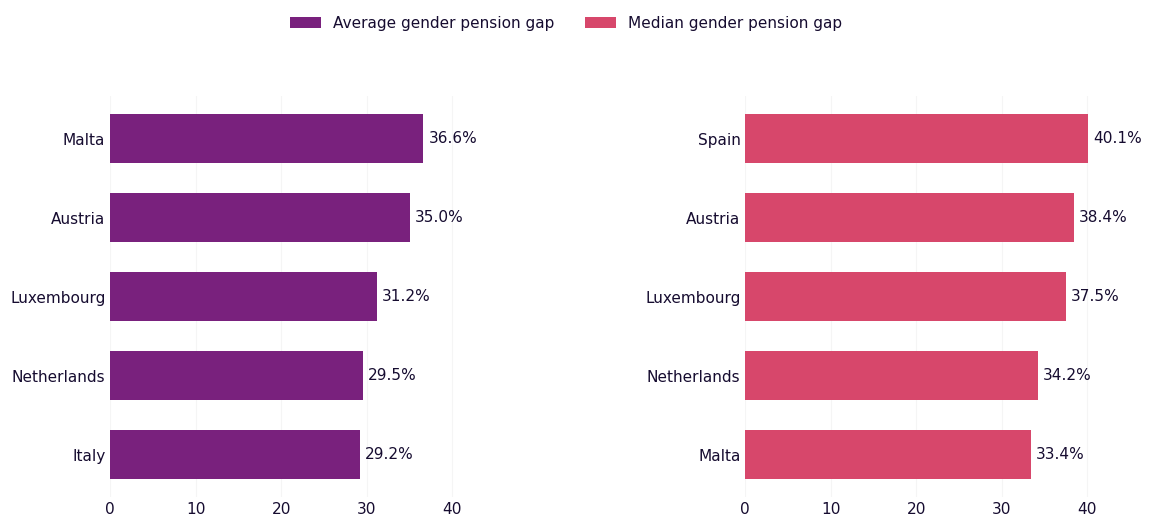

In [91]:
# Compare the five EU countries with the highest average and median
# gender pension gaps in 2025 (age 65+), using side-by-side bar charts.

from matplotlib.patches import Patch

PURPLE = "#79217D"
RASPBERRY = "#D7476B"
NAVY = "#160C30"

top_avg = countries_2025.nlargest(5, "Average")
top_med = countries_2025.nlargest(5, "Median")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, data, metric, color in zip(
    axes,
    [top_avg, top_med],
    ["Average", "Median"],
    [PURPLE, RASPBERRY]
):
    data = data.sort_values(metric)

    bars = ax.barh(
        data["country"],
        data[metric],
        color=color,
        height=0.62
    )

    for bar, value in zip(bars, data[metric]):
        ax.text(
            value + 0.6,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=11,
            color=NAVY
        )

    ax.set_xlim(0, 45)
    ax.set_xticks([0, 10, 20, 30, 40])

    ax.tick_params(
        axis="both",
        length=0,
        labelsize=11,
        colors=NAVY
    )

    ax.grid(axis="x", alpha=0.12)
    ax.set_axisbelow(True)

    # No title or axis label
    ax.set_title("")
    ax.set_xlabel("")

    for spine in ax.spines.values():
        spine.set_visible(False)

# Shared legend above both charts
legend_elements = [
    Patch(facecolor=PURPLE, label="Average gender pension gap"),
    Patch(facecolor=RASPBERRY, label="Median gender pension gap")
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    fontsize=11,
    labelcolor=NAVY
)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.12,
    top=0.85,
    wspace=0.65
)

plt.show()


plt.show()


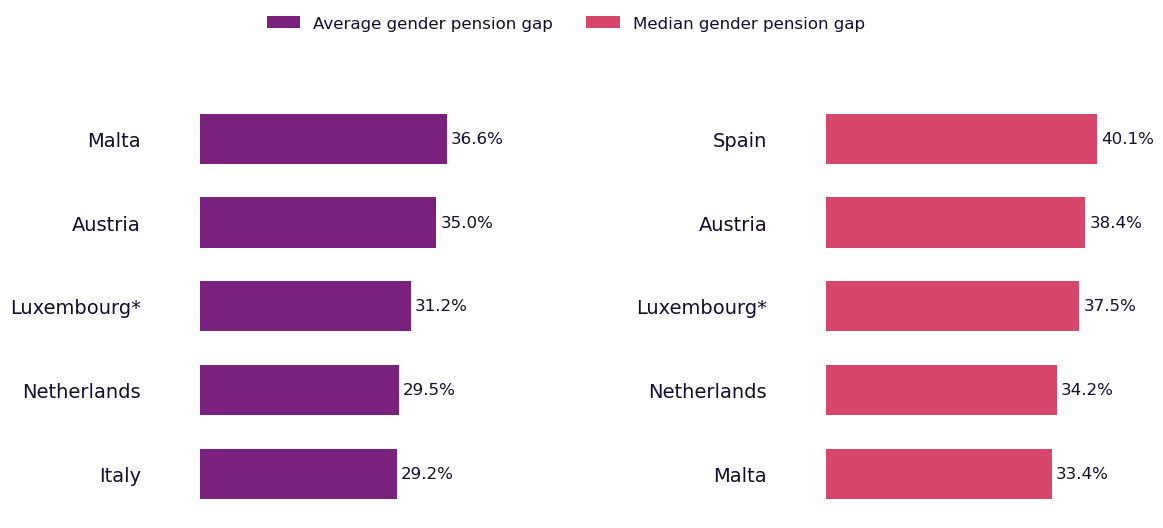

In [92]:
# Add an asterisk for Luxembourg and download image
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, data, metric, color in zip(
    axes,
    [top_avg, top_med],
    ["Average", "Median"],
    [PURPLE, RASPBERRY]
):
    data = data.sort_values(metric, ascending=False).copy()

    # Add an asterisk to Luxembourg's displayed name
    data["country_label"] = data["country"].replace({
        "Luxembourg": "Luxembourg*"
    })

    bars = ax.barh(
        data["country_label"],
        data[metric],
        color=color,
        height=0.60
    )

    ax.invert_yaxis()

    for bar, value in zip(bars, data[metric]):
        ax.text(
            value + 0.6,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=12,
            color=NAVY
        )

    ax.set_xlim(-8, 45)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0, labelsize=14, colors=NAVY)
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Shared legend
legend_elements = [
    Patch(facecolor=PURPLE, label="Average gender pension gap"),
    Patch(facecolor=RASPBERRY, label="Median gender pension gap")
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    fontsize=12,
    labelcolor=NAVY
)

fig.subplots_adjust(
    left=0.15,
    right=0.97,
    bottom=0.08,
    top=0.85,
    wspace=0.75
)

fig.savefig(
    "highest_pension_gaps_clean.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

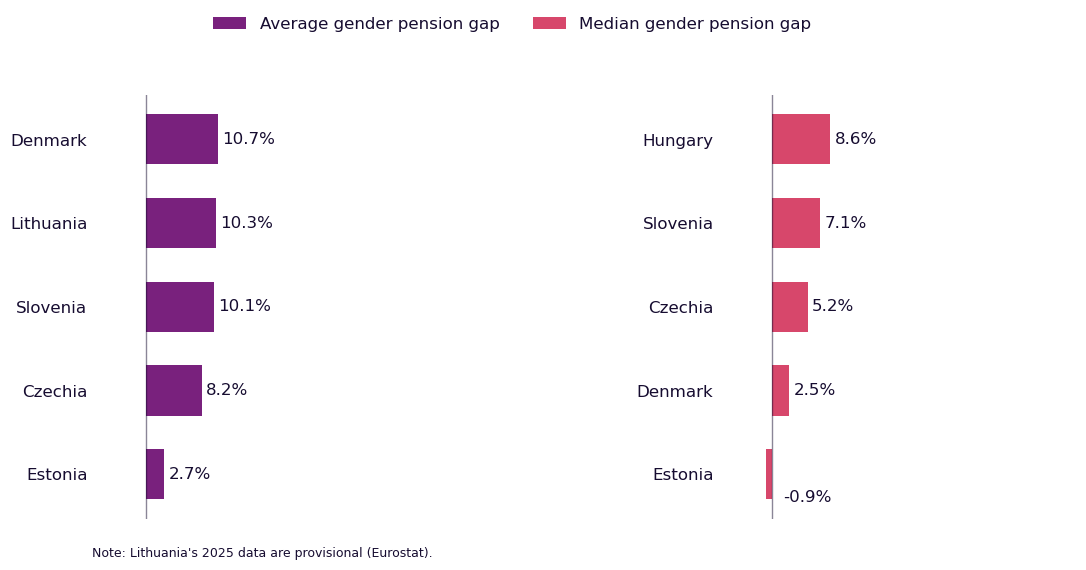

In [93]:
# Compare the five EU countries with the lowest average and median
# gender pension gaps in 2025 (age 65+), using side-by-side bar charts.
bottom_avg = countries_2025.nsmallest(5, "Average")
bottom_med = countries_2025.nsmallest(5, "Median")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, data, metric, color in zip(
    axes,
    [bottom_avg, bottom_med],
    ["Average", "Median"],
    [PURPLE, RASPBERRY]
):
    data = data.sort_values(metric, ascending=False).copy()

    bars = ax.barh(
        data["country"],
        data[metric],
        color=color,
        height=0.60
    )

    ax.invert_yaxis()

    for bar, value in zip(bars, data[metric]):
        if value < 0:
            ax.annotate(
                f"{value:.1f}%",
                xy=(0, bar.get_y() + bar.get_height() / 2),
                xytext=(8, -17),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=12,
                color=NAVY
            )
        else:
            ax.text(
                value + 0.6,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                va="center",
                fontsize=12,
                color=NAVY
            )

    ax.set_xlim(-8, 45)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0, labelsize=12, colors=NAVY)
    ax.grid(False)

    # Keep zero line to explain the negative bar
    ax.axvline(0, color=NAVY, linewidth=1, alpha=0.5)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Shared legend
legend_elements = [
    Patch(facecolor=PURPLE, label="Average gender pension gap"),
    Patch(facecolor=RASPBERRY, label="Median gender pension gap")
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    fontsize=12,
    labelcolor=NAVY
)

fig.subplots_adjust(
    left=0.15,
    right=0.97,
    bottom=0.08,
    top=0.85,
    wspace=0.75
)

fig.text(
    0.15, 0.01,
    "Note: Lithuania's 2025 data are provisional (Eurostat).",
    fontsize=9,
    color=NAVY,
    ha="left"
)

fig.savefig(
    "lowest_pension_gaps_clean.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

### Comparing average and median pension gaps across EU countries

The dumbbell chart compares average and median gender pension gaps across the 27 EU Member States. The distance between the two dots shows the difference between the measures, while the published EU-27 aggregate is included as a benchmark.

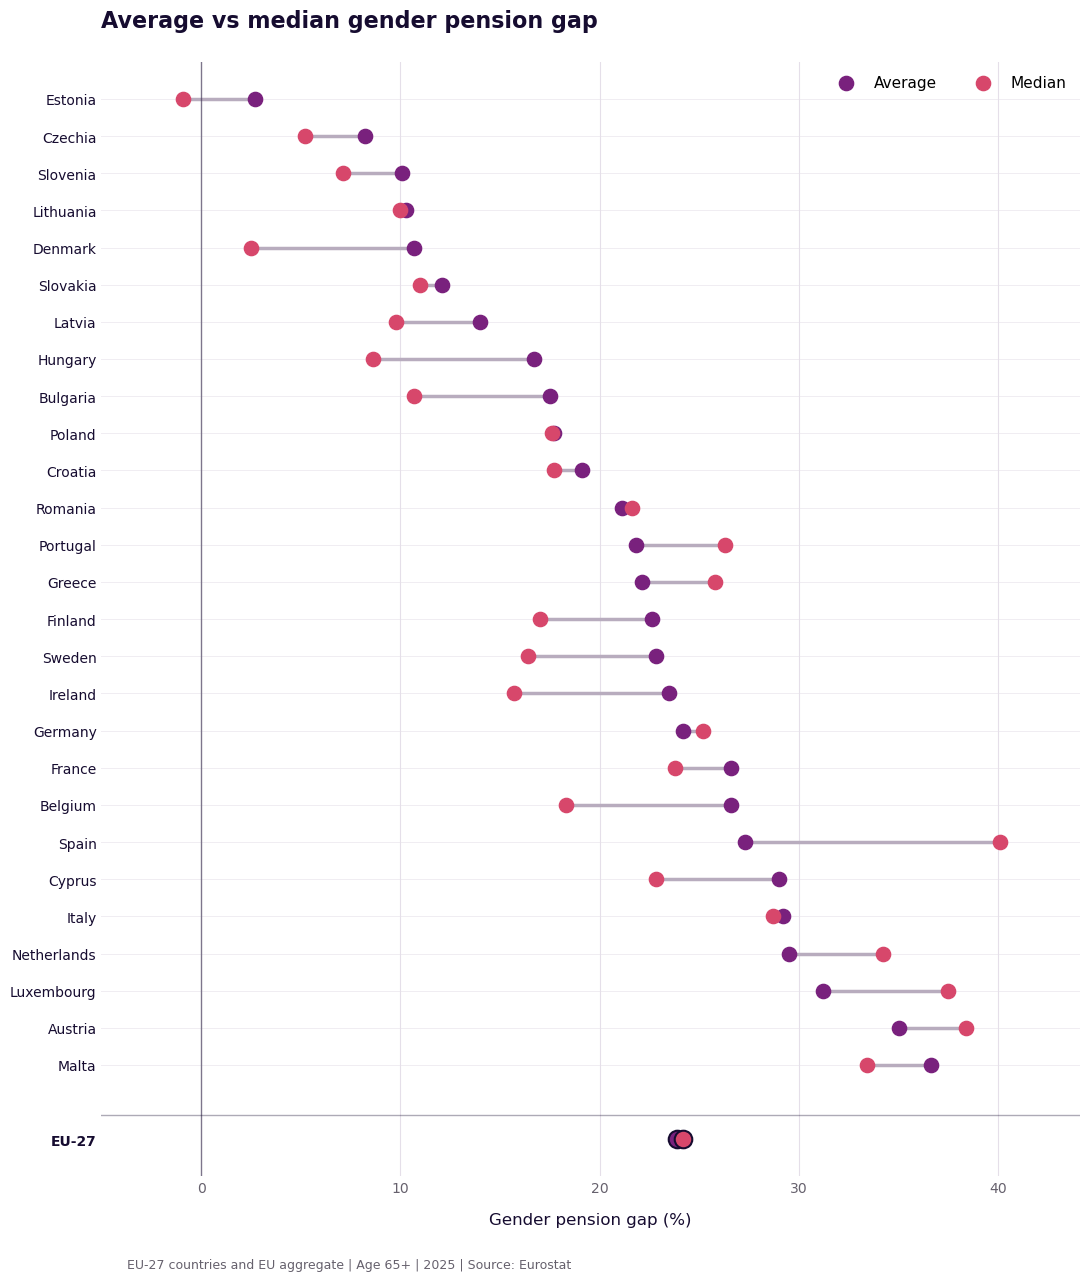

EU-27 average gap: 23.9%
EU-27 median gap: 24.2%
Countries plotted: 27


In [94]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


plot_data = countries_2025[
    countries_2025["country"] != "EU-27"
].copy()

plot_data = plot_data.dropna(
    subset=["Average", "Median"]
)

# Sort countries by average gender pension gap
plot_data = plot_data.sort_values("Average").reset_index(drop=True)

# Retrieve EU-27 aggregate separately
eu_data = df_pension[
    (df_pension["country"] == "EU-27") &
    (df_pension["year"] == 2025) &
    (df_pension["age"] == "Y_GE65") &
    (df_pension["statistic"].isin(["Average", "Median"]))
]

eu_values = eu_data.set_index("statistic")["value"]

eu_avg = float(eu_values["Average"])
eu_med = float(eu_values["Median"])


navy = "#160C30"
purple = "#79217D"
raspberry = "#D7476B"
lavender = "#E5DFE9"
connector = "#B8ACBE"


fig, ax = plt.subplots(figsize=(11, 13))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.arange(len(plot_data))

for pos in y:
    ax.axhline(
        pos,
        color="#F0EDF2",
        linewidth=0.7,
        zorder=0
    )

ax.hlines(
    y=y,
    xmin=plot_data[["Average", "Median"]].min(axis=1),
    xmax=plot_data[["Average", "Median"]].max(axis=1),
    color=connector,
    linewidth=2.5,
    zorder=2
)

# Average pension gap dots
ax.scatter(
    plot_data["Average"],
    y,
    s=105,
    color=purple,
    label="Average",
    zorder=4
)

# Median pension gap dots
ax.scatter(
    plot_data["Median"],
    y,
    s=105,
    color=raspberry,
    label="Median",
    zorder=5
)

# Place EU-27 below the countries, with a blank row
eu_y = len(plot_data) + 1

ax.axhline(
    eu_y - 0.65,
    color=navy,
    linewidth=1,
    alpha=0.35
)

ax.hlines(
    y=eu_y,
    xmin=min(eu_avg, eu_med),
    xmax=max(eu_avg, eu_med),
    color=navy,
    linewidth=2.5,
    zorder=2
)

ax.scatter(
    eu_avg,
    eu_y,
    s=160,
    color=purple,
    edgecolor=navy,
    linewidth=1.5,
    zorder=4
)

ax.scatter(
    eu_med,
    eu_y,
    s=160,
    color=raspberry,
    edgecolor=navy,
    linewidth=1.5,
    zorder=5
)


ax.set_yticks(list(y) + [eu_y])

ax.set_yticklabels(
    list(plot_data["country"]) + ["EU-27"],
    fontsize=10,
    color=navy
)

ax.tick_params(axis="y", length=0)

# Make EU-27 label bold
ax.get_yticklabels()[-1].set_fontweight("bold")

max_gap = max(
    plot_data[["Average", "Median"]].max().max(),
    eu_avg,
    eu_med
)

ax.set_xlim(
    min(-5, plot_data[["Average", "Median"]].min().min() - 2),
    max_gap + 4
)
ax.set_ylim(-1, eu_y + 1)
ax.invert_yaxis()

ax.set_xlabel(
    "Gender pension gap (%)",
    fontsize=12,
    color=navy,
    labelpad=12
)

ax.grid(
    axis="x",
    color=lavender,
    linewidth=0.8
)

ax.axvline(
    0,
    color=navy,
    linewidth=1,
    alpha=0.5
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="x",
    labelsize=10,
    colors="#66616D",
    length=0
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11,
    ncol=2
)

ax.set_title(
    "Average vs median gender pension gap",
    fontsize=16,
    fontweight="bold",
    color=navy,
    loc="left",
    pad=25
)

fig.text(
    0.12,
    0.02,
    "EU-27 countries and EU aggregate | Age 65+ | 2025 | Source: Eurostat",
    fontsize=9,
    color="#66616D"
)


plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    "pension_gap_dumbbell_2025.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Quick validation
print(f"EU-27 average gap: {eu_avg:.1f}%")
print(f"EU-27 median gap: {eu_med:.1f}%")
print(f"Countries plotted: {len(plot_data)}")


In [95]:
# Identify countries with a difference of at least 5 percentage points
large_differences = comparison_2025[
    (comparison_2025["geo"] != "EU27_2020") &
    (comparison_2025["avg_minus_median"].abs() >= 5)
].copy()

large_differences = large_differences.sort_values(
    "avg_minus_median"
)

display(large_differences[
    ["country", "Average", "Median", "avg_minus_median"]
])

statistic,country,Average,Median,avg_minus_median
9,Spain,27.3,40.1,-12.8
18,Luxembourg,31.2,37.5,-6.3
11,Finland,22.6,17.0,5.6
3,Cyprus,29.0,22.8,6.2
25,Sweden,22.8,16.4,6.4
2,Bulgaria,17.5,10.7,6.8
15,Ireland,23.5,15.7,7.8
14,Hungary,16.7,8.6,8.1
6,Denmark,10.7,2.5,8.2
1,Belgium,26.6,18.3,8.3


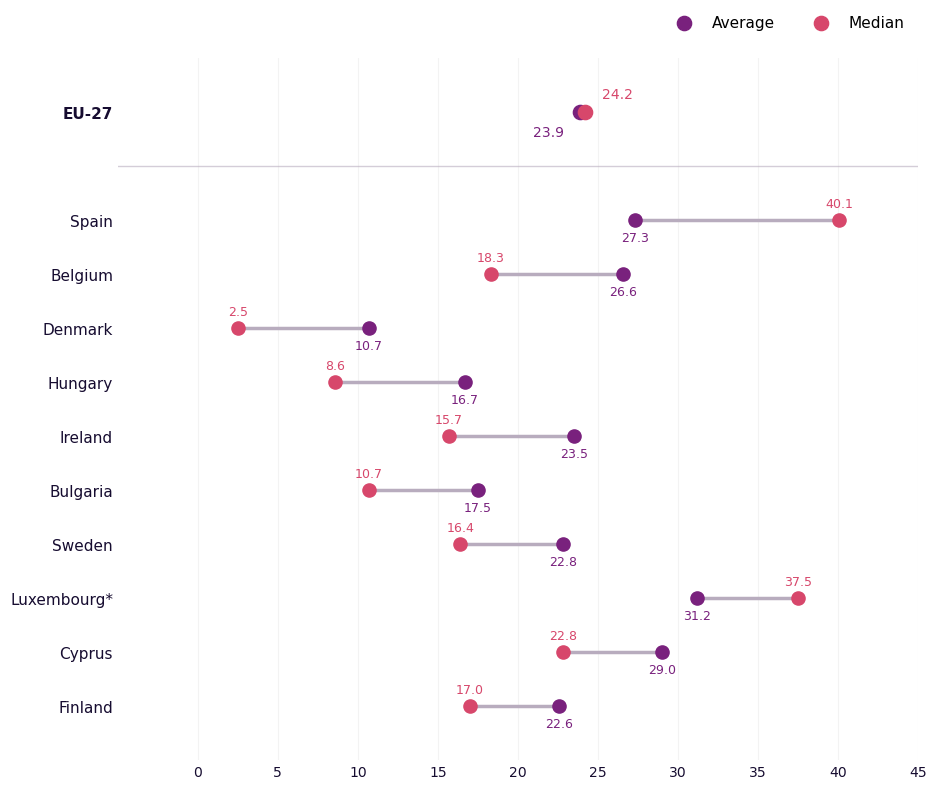

Countries selected: 10


statistic,country,Average,Median,difference
0,Spain,27.3,40.1,-12.8
1,Belgium,26.6,18.3,8.3
2,Denmark,10.7,2.5,8.2
3,Hungary,16.7,8.6,8.1
4,Ireland,23.5,15.7,7.8
5,Bulgaria,17.5,10.7,6.8
6,Sweden,22.8,16.4,6.4
7,Luxembourg,31.2,37.5,-6.3
8,Cyprus,29.0,22.8,6.2
9,Finland,22.6,17.0,5.6


In [96]:
# Select countries with a difference of at least 5 percentage points
dumbbell_data = countries_2025.dropna(
    subset=["Average", "Median"]
).copy()

dumbbell_data["difference"] = (
    dumbbell_data["Average"] - dumbbell_data["Median"]
)

selected = dumbbell_data[
    dumbbell_data["difference"].abs() >= 5
].copy()

# Sort by the size of the difference, largest first
selected = selected.sort_values(
    "difference",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

# Mark Luxembourg's Eurostat quality flag
selected["country_label"] = selected["country"].replace({
    "Luxembourg": "Luxembourg*"
})

# Published EU-27 aggregate
eu_data = comparison_2025.loc[
    comparison_2025["geo"] == "EU27_2020"
].iloc[0]

eu_avg = float(eu_data["Average"])
eu_med = float(eu_data["Median"])

# Colours
PURPLE = "#79217D"
RASPBERRY = "#D7476B"
NAVY = "#160C30"
EU_BLUE = "#2478C8"
CONNECTOR = "#B8ACBE"

# Create chart
fig, ax = plt.subplots(figsize=(10, 9))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# EU benchmark at the top, countries below
eu_y = 0
y_positions = np.arange(2, len(selected) + 2)

# Country dumbbells
for y, (_, row) in zip(y_positions, selected.iterrows()):
    avg = row["Average"]
    med = row["Median"]

    ax.plot(
        [avg, med], [y, y],
        color=CONNECTOR,
        linewidth=2.5,
        zorder=1
    )

    ax.scatter(
        avg, y,
        color=PURPLE,
        s=90,
        zorder=3
    )

    ax.scatter(
        med, y,
        color=RASPBERRY,
        s=90,
        zorder=3
    )

    ax.annotate(
        f"{avg:.1f}",
        (avg, y),
        xytext=(0, -15),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=PURPLE
    )

    ax.annotate(
        f"{med:.1f}",
        (med, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=RASPBERRY
    )

# EU-27 benchmark
ax.plot(
    [eu_avg, eu_med], [eu_y, eu_y],
    color=EU_BLUE,
    linewidth=3,
    zorder=2
)

ax.scatter(
    eu_avg, eu_y,
    color=PURPLE,
    s=105,
    zorder=3,
    label="Average"
)

ax.scatter(
    eu_med, eu_y,
    color=RASPBERRY,
    s=105,
    zorder=4,
    label="Median"
)

# Separate EU labels because the values are close
ax.annotate(
    f"{eu_avg:.1f}",
    (eu_avg, eu_y),
    xytext=(-12, -17),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    color=PURPLE
)

ax.annotate(
    f"{eu_med:.1f}",
    (eu_med, eu_y),
    xytext=(12, 10),
    textcoords="offset points",
    ha="left",
    fontsize=10,
    color=RASPBERRY
)

# Divider below EU benchmark
ax.axhline(
    1,
    color=CONNECTOR,
    linewidth=1,
    alpha=0.6
)

# Country labels
ax.set_yticks([eu_y] + list(y_positions))

ax.set_yticklabels(
    ["EU-27"] + selected["country_label"].tolist(),
    fontsize=11,
    color=NAVY
)

ax.get_yticklabels()[0].set_fontweight("bold")

# Axes
ax.set_xlim(-5, 45)
ax.set_ylim(-1, len(selected) + 2)
ax.invert_yaxis()

ax.set_xticks(np.arange(0, 46, 5))

ax.tick_params(
    axis="x",
    colors=NAVY,
    length=0
)

ax.tick_params(
    axis="y",
    length=0
)

ax.grid(
    axis="x",
    alpha=0.15
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

# Legend above the plotting area
ax.legend(
    loc="lower right",
    bbox_to_anchor=(1, 1.02),
    ncol=2,
    frameon=False,
    fontsize=11
)

# Layout and export
fig.subplots_adjust(
    left=0.16,
    right=0.96,
    bottom=0.10,
    top=0.88
)

fig.savefig(
    "dumbbell_5pp_difference_2025.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

# Check selected countries
print("Countries selected:", len(selected))

display(
    selected[
        ["country", "Average", "Median", "difference"]
    ]
)

**In 2025, ten of the 27 EU Member States (37%) recorded differences exceeding 5 percentage points between their average and median gender pension gaps. In eight of these countries, the average gap was higher than the median; in Spain and Luxembourg, the opposite was true.**

In [97]:
# Counting countries where the average or median pension gap is higher
countries_2025 = comparison_2025[
    comparison_2025["geo"] != "EU27_2020"
].copy()

average_higher = (countries_2025["Average"] > countries_2025["Median"]).sum()
median_higher = (countries_2025["Median"] > countries_2025["Average"]).sum()
equal = (countries_2025["Average"] == countries_2025["Median"]).sum()

print(f"Average gap higher: {average_higher} countries")
print(f"Median gap higher: {median_higher} countries")
print(f"Equal gaps: {equal} countries")

Average gap higher: 19 countries
Median gap higher: 8 countries
Equal gaps: 0 countries


**In 2025, the average gender pension gap was higher than the median in 19 of the 27 EU Member States, while the median gap was higher in the remaining eight. Estonia stands out: its average gap was positive (2.7%), while its median gap was slightly negative (−0.9%), indicating a small advantage for women at the median.**

In [98]:
countries_2025 = comparison_2025[
    comparison_2025["geo"] != "EU27_2020"
].copy()

Correlation: 0.901


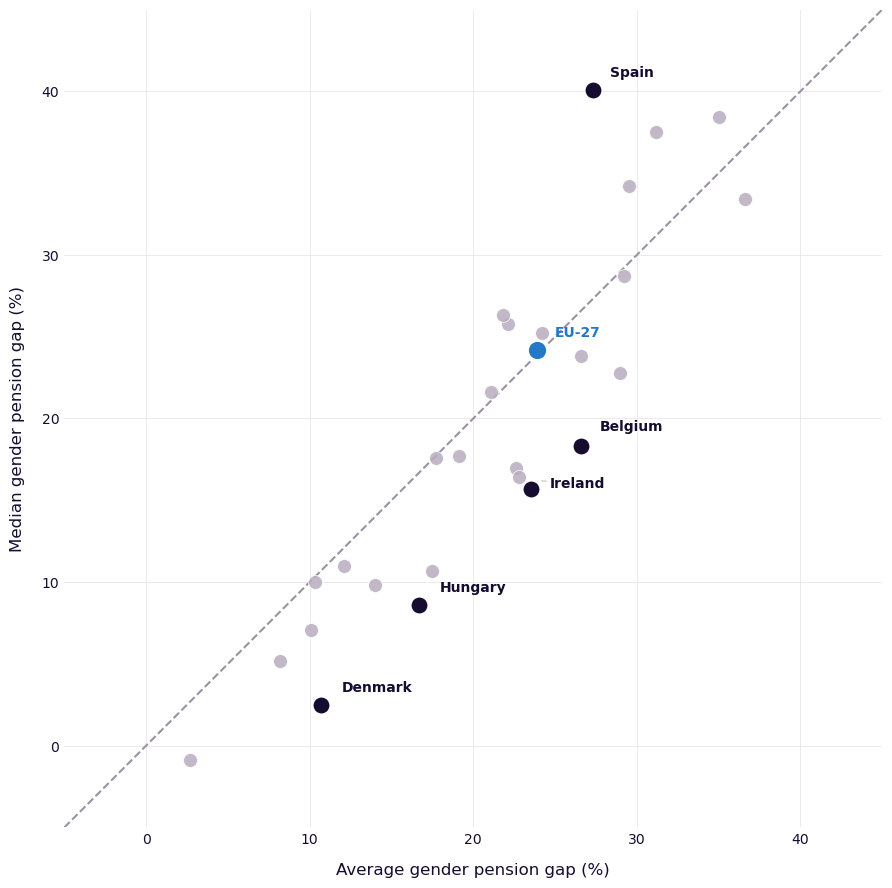

statistic,country,Average,Median,difference
9,Spain,27.3,40.1,-12.8
1,Belgium,26.6,18.3,8.3
6,Denmark,10.7,2.5,8.2
14,Hungary,16.7,8.6,8.1
15,Ireland,23.5,15.7,7.8


In [99]:
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

# Compare average and median gender pension gaps across EU countries
# in 2025 (age 65+), highlighting the five largest differences.

# Prepare country data, excluding the EU aggregate
plot_data = comparison_2025[
    comparison_2025["geo"] != "EU27_2020"
].dropna(subset=["Average", "Median"]).copy()

plot_data["difference"] = (
    plot_data["Average"] - plot_data["Median"]
)

# Select the five countries with the largest absolute differences
highlight_data = (
    plot_data.assign(
        abs_difference=plot_data["difference"].abs()
    )
    .nlargest(5, "abs_difference")
)

# Published EU-27 aggregate
eu_data = comparison_2025.loc[
    comparison_2025["geo"] == "EU27_2020"
].iloc[0]

eu_avg = float(eu_data["Average"])
eu_med = float(eu_data["Median"])

# Correlation between average and median gaps
correlation = plot_data["Average"].corr(
    plot_data["Median"]
)

print(f"Correlation: {correlation:.3f}")

# Colours
NAVY = "#160C30"
LAVENDER_GREY = "#B8ACBE"
EU_BLUE = "#2478C8"
GRID = "#E5DFE9"

# Calculate shared axis limits
all_values = np.concatenate([
    plot_data["Average"].to_numpy(),
    plot_data["Median"].to_numpy(),
    [eu_avg, eu_med]
])

axis_min = np.floor(
    (min(0, all_values.min()) - 3) / 5
) * 5

axis_max = np.ceil(
    (all_values.max() + 3) / 5
) * 5

# Create figure
fig, ax = plt.subplots(figsize=(9, 9))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Equality line: average = median
ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--",
    color="#9B93A4",
    linewidth=1.5,
    zorder=1
)

# All EU countries
ax.scatter(
    plot_data["Average"],
    plot_data["Median"],
    s=100,
    color=LAVENDER_GREY,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.6,
    zorder=3
)

# Highlight five largest absolute differences
ax.scatter(
    highlight_data["Average"],
    highlight_data["Median"],
    s=150,
    color=NAVY,
    edgecolor="white",
    linewidth=0.8,
    zorder=4
)

# EU-27 benchmark
ax.scatter(
    eu_avg,
    eu_med,
    s=180,
    color=EU_BLUE,
    edgecolor="white",
    linewidth=1,
    zorder=5
)

# Label highlighted countries
texts = []

for _, row in highlight_data.iterrows():
    texts.append(
        ax.text(
            row["Average"] + 0.5,
            row["Median"] + 0.5,
            row["country"],
            fontsize=10,
            color=NAVY,
            fontweight="bold",
            zorder=6
        )
    )

# Label EU-27
texts.append(
    ax.text(
        eu_avg + 0.5,
        eu_med + 0.5,
        "EU-27",
        fontsize=10,
        color=EU_BLUE,
        fontweight="bold",
        zorder=6
    )
)

# Reduce label overlap
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="#B8ACBE",
        lw=0.6
    )
)

# Axes and formatting
ax.set_xlim(axis_min, axis_max)
ax.set_ylim(axis_min, axis_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    "Average gender pension gap (%)",
    fontsize=12,
    color=NAVY,
    labelpad=12
)

ax.set_ylabel(
    "Median gender pension gap (%)",
    fontsize=12,
    color=NAVY,
    labelpad=12
)

ax.grid(
    color=GRID,
    linewidth=0.7,
    alpha=0.7
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0,
    labelsize=10
)

for spine in ax.spines.values():
    spine.set_visible(False)

# Save and display
plt.tight_layout()

fig.savefig(
    "pension_gap_scatterplot_2025.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Display highlighted countries
display(
    highlight_data[
        ["country", "Average", "Median", "difference"]
    ]
)

**The scatterplot shows that average and median gender pension gaps generally follow a similar pattern across EU countries, but the differences between the two measures can be substantial. Countries further from the dashed equality line show the greatest discrepancies, highlighting how the choice of measure can affect comparisons between countries.**

In [100]:
correlation = countries_2025["Average"].corr(
    countries_2025["Median"]
)

print("Correlation:", round(correlation, 3))

Correlation: 0.901


### Strong correlation, but notable differences

For people aged 65+ in 2025, average and median gender pension gaps are strongly positively correlated across EU Member States (Pearson's r = 0.901).

Countries with higher average pension gaps generally also have higher median gaps. However, the two measures are not interchangeable: the size of the gap can differ considerably depending on which measure is used.

# A closer look at Spain

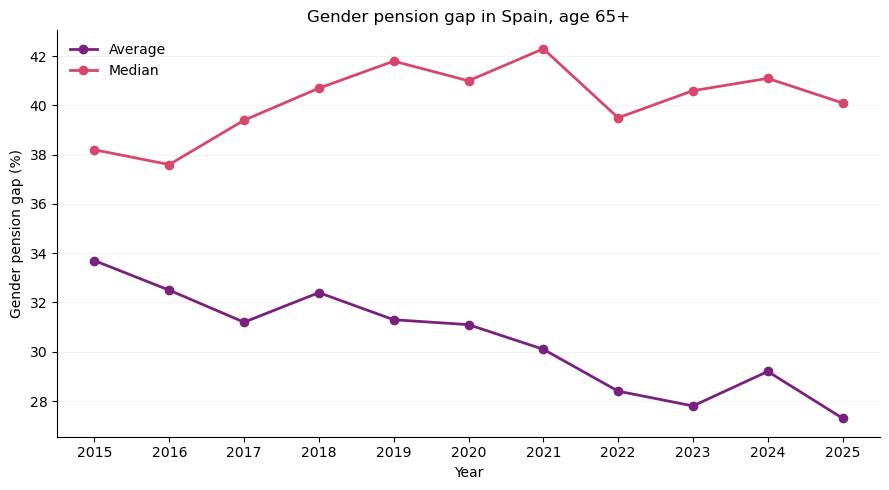

In [101]:
# Compare the evolution of average and median gender pension gaps
# in Spain from 2015 to 2025 (age 65+).

spain = df_pension[
    (df_pension["country"] == "Spain") &
    (df_pension["age"] == "Y_GE65")
].sort_values("year")

fig, ax = plt.subplots(figsize=(9, 5))

for statistic, color in [
    ("Average", "#79217D"),
    ("Median", "#D7476B")
]:
    subset = spain[spain["statistic"] == statistic]

    ax.plot(
        subset["year"],
        subset["value"],
        marker="o",
        linewidth=2,
        color=color,
        label=statistic
    )

ax.set_xlabel("Year")
ax.set_ylabel("Gender pension gap (%)")
ax.set_title("Gender pension gap in Spain, age 65+")
ax.legend(frameon=False)
ax.set_xticks(sorted(spain["year"].unique()))

ax.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

Between 2015 and 2025, Spain's average gender pension gap (age 65+) decreased from **33.7% to 27.3%**, while its median gap increased from **38.2% to 40.1%**.

As a result, the difference between the two measures widened from **4.5 to 12.8 percentage points**.

This illustrates how average and median indicators can lead to different conclusions about the evolution of gender pension inequality.

**Methodological note — Spain**  Eurostat's Spanish EU-SILC quality annex reports a weighting revision in 2024 (https://ec.europa.eu/eurostat/cache/metadata/Annexes/ilc_simsilc_es_an_8.xlsx), classified as having a moderate impact requiring caution in time comparisons, although no break in series was flagged. Changes to panel household follow-up during 2020–2022 were classified as negligible. No specific impact on the gender pension gap indicators was quantified.

# Conclusions

So far, the analysis highlights the importance of considering both average and median gender pension gaps when examining pension inequality across EU countries. 

Although the measures generally follow similar patterns, differences in country rankings, gap sizes and trends over time show that relying on a single indicator can provide an incomplete picture.
